# 신용 점수·연체 예측 — 한 단계씩 실행하며 배우기

가상의 고객 10,000명의 정보(나이, 소득, 부채 비율 등 6가지)로 두 가지를 예측한다.

- **신용 점수**(0~1000의 숫자) → 숫자를 맞히는 **회귀**
- **연체 여부**(0 = 정상, 1 = 연체) → 둘 중 하나를 고르는 **분류**

먼저 사람이 만든 if문 규칙으로 예측해 보고, 머신러닝 모델이 무엇을 더 잘하는지 숫자로 비교한다.

**사용법:** 위에서부터 한 셀씩 실행한다(전체 실행은 1분 이내). 코드를 한 줄씩 이해하지 못해도 괜찮다. 각 셀 아래의 **출력 읽기**가 출력에서 무엇을 보면 되는지 알려준다. **확인 질문**은 먼저 자기 말로 답해 본 뒤 접힌 답을 연다.

**구성:** 1~10장이 본편이다. 부록(A~E)은 더 알고 싶을 때 보는 확장이다. 데이터는 연습용으로 만든 합성 데이터라서, 결과를 실제 금융 고객에 대한 결론으로 읽지 않는다.

## 0. 준비

도구를 불러오고, 데이터 파일이 있는 프로젝트 폴더를 찾는다. 머신러닝 계산은 1장부터 시작한다.

In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_root = None
for candidate_folder in [Path.cwd()] + list(Path.cwd().parents):
    if (candidate_folder / "data_gen.py").is_file() and (candidate_folder / "src").is_dir():
        project_root = candidate_folder
        break

if project_root is None:
    raise FileNotFoundError("A5-1 폴더를 찾지 못했습니다. A5-1 또는 notebooks에서 실행하세요.")

RANDOM_STATE = 42  # 무작위 과정(분할 등)을 매번 같게 재현하기 위한 번호
pd.set_option("display.precision", 4)
print("프로젝트:", project_root.name)

프로젝트: A5-1


## 1. 데이터 — 입력과 정답

데이터는 함께 제공된 생성 코드(`data_gen.py`)로 만든다. 생성 규칙은 이렇다.

- 신용 점수 = 소득·부채 비율·최근 6개월 연체 횟수로 계산한 값 + 무작위 잡음
- 연체 = 신용 점수 하위 15%인 고객 중 무작위로 약 80%

그래서 전체 고객의 약 12%가 연체다. 나이·소비 점수·카드 수는 어느 정답에도 쓰이지 않은 변수다. 모델이 이 사실을 알아내는지 나중에 확인한다.

In [2]:
data_path = project_root / "finance_data.csv"
if not data_path.exists():
    subprocess.run([sys.executable, str(project_root / "data_gen.py")],
                   cwd=project_root, check=True)

customers = pd.read_csv(data_path)
print("고객 수:", len(customers))
print("연체 비율:", customers["is_overdue"].mean())
display(customers.head())

고객 수: 10000
연체 비율: 0.1201


,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m,credit_score,is_overdue
0,50,3406.0,54,0.29,1,1,295.0,0
1,25,2161.0,7,0.78,2,0,259.0,1
2,56,6390.0,83,0.88,9,2,323.0,0
3,54,2821.0,10,0.01,2,2,377.0,0
4,50,4925.0,90,0.06,7,1,395.0,0


머신러닝에서는 예측할 때 받는 정보를 **X(입력)**, 맞혀야 할 답을 **y(정답)**라고 부른다. 정답 열 두 개는 입력에서 뺀다. 특히 연체 라벨은 신용 점수로 만들었으므로, 신용 점수를 입력에 넣으면 답을 보고 문제를 푸는 셈이다. 이것을 **정답 누수**라고 한다.

In [3]:
feature_columns = [
    "age", "annual_income", "spending_score", "debt_ratio",
    "credit_card_count", "overdue_count_6m",
]
X = customers[feature_columns]
y_classification = customers["is_overdue"]   # 분류 정답: 0 또는 1
y_regression = customers["credit_score"]     # 회귀 정답: 점수

print("X의 크기 (행, 열):", X.shape)
display(X.head(3))

X의 크기 (행, 열): (10000, 6)


,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m
0,50,3406.0,54,0.29,1,1
1,25,2161.0,7,0.78,2,0
2,56,6390.0,83,0.88,9,2


**확인 질문:** 신용 점수도 숫자이고 연체 여부도 0/1 숫자인데, 왜 하나는 회귀이고 하나는 분류일까?
<details><summary>답 확인</summary>신용 점수는 크기에 의미가 있어 "얼마나 틀렸나"(오차)로 평가한다. 0/1은 정상/연체라는 두 범주에 붙인 이름표일 뿐이라 "맞혔나 틀렸나"로 평가한다. 숫자로 저장됐는지가 아니라 무엇을 예측하고 어떻게 평가하는지가 다르다.</details>

## 2. 분할 — 공부용 데이터와 시험용 데이터

모델이 본 데이터로 채점하면 실력을 알 수 없다. 그래서 고객을 8:2로 나눠 **Train**(학습용 8,000명)으로만 학습하고, **Test**(시험용 2,000명)는 마지막 채점에만 쓴다.

`stratify`는 두 묶음의 연체 비율을 비슷하게 맞추라는 뜻이다. 연체자가 12%뿐이라 그냥 나누면 한쪽에 몰릴 수 있다.

In [4]:
from sklearn.model_selection import train_test_split

(X_train, X_test,
 y_classification_train, y_classification_test,
 y_regression_train, y_regression_test) = train_test_split(
    X, y_classification, y_regression,
    test_size=0.2, random_state=RANDOM_STATE, stratify=y_classification,
)

display(pd.DataFrame({
    "customers": [len(X_train), len(X_test)],
    "overdue_rate": [y_classification_train.mean(), y_classification_test.mean()],
}, index=["Train", "Test"]))

,customers,overdue_rate
Train,8000,0.1201
Test,2000,0.1200


## 3. 사람이 만든 규칙으로 예측하기

학습 없이 if문만으로 예측하면 얼마나 맞힐까? 아래 6개 조건 중 하나라도 해당하면 연체(1), 아니면 정상(0)으로 판정한다. 이 규칙이 비교의 출발점(**베이스라인**)이 된다.

In [5]:
def predict_by_rules(customer):
    if customer["overdue_count_6m"] >= 2:
        return 1
    if customer["debt_ratio"] > 0.8:
        return 1
    if customer["annual_income"] < 3000:
        return 1
    if customer["overdue_count_6m"] >= 1 and customer["debt_ratio"] > 0.6:
        return 1
    if customer["annual_income"] < 4000 and customer["debt_ratio"] > 0.5:
        return 1
    if customer["credit_card_count"] >= 8:
        return 1
    return 0

# apply(..., axis=1): Test 고객을 한 명(한 행)씩 함수에 넣는다.
rule_predictions = X_test.apply(predict_by_rules, axis=1)
print("규칙이 연체로 판정한 고객:", rule_predictions.sum(), "/", len(rule_predictions))
print("실제 연체 고객:", y_classification_test.sum())

규칙이 연체로 판정한 고객: 1202 / 2000
실제 연체 고객: 240


**출력 읽기:** 실제 연체자는 240명인데 규칙은 그보다 훨씬 많은 고객을 연체로 찍었다. 많이 찍으면 연체자는 많이 잡지만, 정상 고객도 많이 걸린다. 이것을 정확히 세는 도구가 다음 장의 혼동행렬이다.

## 4. 결과 세기 — 혼동행렬과 평가 지표

분류 결과는 "실제"와 "예측"의 조합 네 칸으로 셀 수 있다. 이 표를 **혼동행렬**이라고 한다.

| | 예측: 정상 | 예측: 연체 |
| --- | --- | --- |
| **실제: 정상** | TN (맞게 통과) | FP (정상인데 연체로 찍음) |
| **실제: 연체** | FN (연체자를 놓침) | TP (연체자를 잡음) |

In [6]:
from sklearn.metrics import confusion_matrix

rule_matrix = confusion_matrix(y_classification_test, rule_predictions)
display(pd.DataFrame(rule_matrix,
                     index=["실제: 정상", "실제: 연체"],
                     columns=["예측: 정상", "예측: 연체"]))

tn, fp, fn, tp = rule_matrix.ravel()   # 네 칸을 순서대로 꺼낸다
print("TN:", tn, " FP:", fp, " FN:", fn, " TP:", tp)

,예측: 정상,예측: 연체
실제: 정상,792,968
실제: 연체,6,234


TN: 792  FP: 968  FN: 6  TP: 234


**출력 읽기:** 행(가로줄)은 실제, 열(세로줄)은 예측이다.

- 가로줄을 더하면 실제 인원이다. "실제: 정상" 줄의 합은 Test의 정상 고객 수, "실제: 연체" 줄의 합은 연체자 수(240명)다.
- 세로줄을 더하면 예측 인원이다. "예측: 연체" 열의 합은 3장에서 규칙이 연체로 판정한 고객 수와 같다.

TN·FP·FN·TP는 두 글자로 읽는다. 뒤 글자 **P/N**은 무엇으로 예측했나(Positive = 연체, Negative = 정상), 앞 글자 **T/F**는 그 예측이 맞았나(True = 맞음, False = 틀림)다. 예를 들어 FP는 "연체라고 예측했는데 틀렸다", 즉 정상 고객을 잘못 찍은 경우다.

이제 네 칸으로 주요 지표를 직접 계산한다.

- **Accuracy(정확도)** = 맞힌 수 / 전체 = (TN + TP) / 전체
- **Precision(정밀도)** = 연체로 찍은 사람 중 진짜 연체자 비율 = TP / (TP + FP)
- **Recall(재현율)** = 실제 연체자 중 잡아낸 비율 = TP / (TP + FN)
- **F1** = Precision과 Recall의 조화평균. 둘 중 하나라도 낮으면 F1도 낮다.

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_by_hand = (tn + tp) / (tn + fp + fn + tp)
precision_by_hand = tp / (tp + fp)
recall_by_hand = tp / (tp + fn)
f1_by_hand = 2 * precision_by_hand * recall_by_hand / (precision_by_hand + recall_by_hand)

display(pd.DataFrame({
    "by_hand": [accuracy_by_hand, precision_by_hand, recall_by_hand, f1_by_hand],
    "sklearn": [accuracy_score(y_classification_test, rule_predictions),
                precision_score(y_classification_test, rule_predictions),
                recall_score(y_classification_test, rule_predictions),
                f1_score(y_classification_test, rule_predictions)],
}, index=["accuracy", "precision", "recall", "f1"]))

,by_hand,sklearn
accuracy,0.5130,0.5130
precision,0.1947,0.1947
recall,0.9750,0.9750
f1,0.3245,0.3245


**출력 읽기:** 손으로 센 값과 라이브러리 값이 같다. 규칙은 Recall이 높지만(연체자를 거의 다 잡음) Precision이 낮다(연체로 찍은 다섯 명 중 네 명은 정상 고객).

**확인 질문:** 모든 고객을 "정상"이라고 예측하면 Accuracy와 F1은 어떻게 될까? 실행 전에 예상해 본다.

In [8]:
all_normal_predictions = np.zeros(len(y_classification_test), dtype=int)
print("모두 정상 — Accuracy:", accuracy_score(y_classification_test, all_normal_predictions))
print("모두 정상 — F1:", f1_score(y_classification_test, all_normal_predictions, zero_division=0))

모두 정상 — Accuracy: 0.88
모두 정상 — F1: 0.0


<details><summary>답 확인</summary>정상 고객이 88%이므로 Accuracy는 0.88로 높아 보인다. 하지만 연체자를 한 명도 잡지 못해 TP가 0이고 F1도 0이다. 한쪽이 훨씬 많은 데이터에서는 Accuracy만 보면 속는다. 그래서 이 노트북은 주로 F1을 함께 본다.</details>

## 5. 첫 머신러닝 모델 — 로지스틱 회귀

이름에 "회귀"가 붙었지만 0/1을 고르는 **분류** 모델이다. 네 단계로 진행한다.

1. **전처리:** 숫자 크기를 맞춘다.
2. **학습(`fit`):** Train으로 규칙을 배운다.
3. **예측(`predict`):** Test 고객을 판정한다.
4. **평가:** 4장의 지표로 채점한다.

전처리부터 한다. 소득(수천 단위)과 부채 비율(0~1)은 크기가 전혀 달라서, 각 열을 "평균 0, 표준편차 1"로 바꾼다(**표준화**). 비어 있는 값을 중앙값으로 채우는 단계도 넣는다. 이 데이터에는 빈 값이 없지만, 새 데이터에는 생길 수 있다.

중요한 점은 평균·중앙값 같은 기준을 **Train에서만** 배운다는 것이다. `fit_transform`은 "기준을 배우고 바꾸기", `transform`은 "이미 배운 기준으로 바꾸기"다.

In [9]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)   # Train으로 중앙값을 배우고 채움
X_test_imputed = imputer.transform(X_test)         # 배운 중앙값으로 채우기만 함

scaler = StandardScaler()
X_train_prepared = scaler.fit_transform(X_train_imputed)
X_test_prepared = scaler.transform(X_test_imputed)

display(pd.DataFrame({
    "before (Train)": X_train.iloc[0].to_numpy(),
    "after (Train)": X_train_prepared[0],
}, index=feature_columns))

,before (Train),after (Train)
age,40.00,-0.3316
annual_income,4613.00,-0.2182
spending_score,16.00,-1.1737
debt_ratio,0.98,1.6651
credit_card_count,7.00,0.7710
overdue_count_6m,0.00,-0.7060


**출력 읽기:** 첫 번째 Train 고객의 값이 표준화 전후로 어떻게 바뀌었는지 본다. 0보다 크면 평균보다 큰 값, 작으면 평균보다 작은 값이다.

이제 학습하고 예측한다. `predict_proba`는 고객마다 [정상일 확률, 연체일 확률] 두 숫자를 준다. `[:, 1]`은 그중 두 번째 열인 연체 확률만 꺼낸다.

In [10]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
logistic_model.fit(X_train_prepared, y_classification_train)

predicted_labels = logistic_model.predict(X_test_prepared)
overdue_probabilities = logistic_model.predict_proba(X_test_prepared)[:, 1]

display(pd.DataFrame({
    "actual": y_classification_test.to_numpy()[:8],
    "overdue_probability": overdue_probabilities[:8],
    "prediction": predicted_labels[:8],
}))

,actual,overdue_probability,prediction
0,1,0.1194,0
1,0,0.0228,0
2,0,0.0469,0
3,0,0.0063,0
4,1,0.8208,1
5,0,0.0185,0
6,1,0.5826,1
7,0,0.0004,0


**출력 읽기:** 확률이 0.5 이상인 고객이 1(연체)로 판정됐다. `predict`는 "연체 확률 ≥ 0.5이면 1"이라는 기준을 쓴다. 아래 셀에서 이것을 확인한다.

In [11]:
labels_at_half = (overdue_probabilities >= 0.5).astype(int)
print("predict와 '확률 >= 0.5' 판정이 모두 같은가:", np.array_equal(predicted_labels, labels_at_half))

predict와 '확률 >= 0.5' 판정이 모두 같은가: True


In [12]:
logistic_matrix = confusion_matrix(y_classification_test, predicted_labels)
display(pd.DataFrame(logistic_matrix,
                     index=["실제: 정상", "실제: 연체"],
                     columns=["예측: 정상", "예측: 연체"]))

display(pd.DataFrame({
    "rules": [accuracy_score(y_classification_test, rule_predictions),
              precision_score(y_classification_test, rule_predictions),
              recall_score(y_classification_test, rule_predictions),
              f1_score(y_classification_test, rule_predictions)],
    "logistic": [accuracy_score(y_classification_test, predicted_labels),
                 precision_score(y_classification_test, predicted_labels),
                 recall_score(y_classification_test, predicted_labels),
                 f1_score(y_classification_test, predicted_labels)],
}, index=["accuracy", "precision", "recall", "f1"]))

,예측: 정상,예측: 연체
실제: 정상,1703,57
실제: 연체,102,138


,rules,logistic
accuracy,0.5130,0.9205
precision,0.1947,0.7077
recall,0.9750,0.5750
f1,0.3245,0.6345


**출력 읽기:** 모델은 규칙보다 F1이 두 배 가까이 높다. 정상 고객을 덜 잘못 찍어서(FP 감소) Precision이 크게 올랐다. 대신 Recall은 내려갔다. 연체자 240명 중 100명 이상을 놓친다(FN).

**확인 질문:** 왜 Test에는 `fit_transform`이 아니라 `transform`만 썼을까?
<details><summary>답 확인</summary>Test는 시험지다. Test의 평균으로 기준을 다시 배우면 시험지 정보가 학습에 섞인다. 실제 서비스에서 새 고객이 들어올 때도, 학습할 때 정한 기준으로 바꾼다.</details>

## 6. 임계값 — 0.5는 바꿀 수 있다

5장의 모델은 연체자를 꽤 놓쳤다. 모델을 바꾸지 않고, 판정 기준(**임계값**)만 0.5에서 내려 보면 어떻게 될까?

In [13]:
threshold_rows = []
for threshold in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    labels_at_threshold = (overdue_probabilities >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "flagged": labels_at_threshold.sum(),
        "precision": precision_score(y_classification_test, labels_at_threshold),
        "recall": recall_score(y_classification_test, labels_at_threshold),
        "f1": f1_score(y_classification_test, labels_at_threshold),
    })
display(pd.DataFrame(threshold_rows))

,threshold,flagged,precision,recall,f1
0,0.2,345,0.5623,0.8083,0.6632
1,0.3,282,0.6454,0.7583,0.6973
2,0.4,237,0.6667,0.6583,0.6625
3,0.5,195,0.7077,0.5750,0.6345
4,0.6,151,0.7483,0.4708,0.5780
5,0.7,113,0.7611,0.3583,0.4873


**출력 읽기:** 임계값을 내리면 더 많은 고객을 연체로 찍는다(`flagged` 증가). 그러면 Recall은 오르고 Precision은 내려간다. 이 모델은 F1이 0.5보다 0.3 근처에서 더 높다. 같은 모델에서도 기준에 따라 판정과 지표가 바뀐다.

여기서는 변화를 관찰하려고 Test를 썼다. 실제로 임계값을 **정할** 때는 Test가 아니라 Train으로 정해야 한다(부록 B).

### 6-1. ROC-AUC — 임계값과 상관없는 점수

임계값마다 지표가 바뀌니, 기준과 무관하게 모델을 평가할 방법도 필요하다. **ROC-AUC**는 이렇게 읽는다.

> 연체자 한 명과 정상 고객 한 명을 무작위로 뽑았을 때, 모델이 연체자에게 더 높은 위험 점수를 줄 확률

1.0이면 항상 연체자를 더 위험하게 보고, 0.5면 동전 던지기 수준이다. 아래에서 실제로 무작위 쌍을 뽑아 확인한다.

In [14]:
from sklearn.metrics import roc_auc_score

y_test_array = y_classification_test.to_numpy()
overdue_scores = overdue_probabilities[y_test_array == 1]
normal_scores = overdue_probabilities[y_test_array == 0]

rng = np.random.default_rng(RANDOM_STATE)
picked_overdue = rng.choice(overdue_scores, size=10_000)
picked_normal = rng.choice(normal_scores, size=10_000)
print("무작위 10,000쌍에서 연체자 점수가 더 높은 비율:", np.mean(picked_overdue > picked_normal))
print("roc_auc_score:", roc_auc_score(y_classification_test, overdue_probabilities))

무작위 10,000쌍에서 연체자 점수가 더 높은 비율: 0.9488
roc_auc_score: 0.9505089962121213


**출력 읽기:** 두 값이 거의 같다. AUC는 "순서를 얼마나 잘 매기는가"를 잰다.

규칙에도 AUC를 매길 수 있다. 0/1 판정 대신 "걸린 규칙의 개수"를 위험 점수로 쓰면 된다. 아래 그래프(**ROC 곡선**)는 임계값을 바꿔 가며 x축 오탐률(정상 고객을 잘못 찍은 비율)과 y축 재현율을 이은 선이다. 선 아래 넓이가 AUC다.

In [15]:
def count_risk_rules(customer):
    count = 0
    count += int(customer["overdue_count_6m"] >= 2)
    count += int(customer["debt_ratio"] > 0.8)
    count += int(customer["annual_income"] < 3000)
    count += int(customer["overdue_count_6m"] >= 1 and customer["debt_ratio"] > 0.6)
    count += int(customer["annual_income"] < 4000 and customer["debt_ratio"] > 0.5)
    count += int(customer["credit_card_count"] >= 8)
    return count

rule_scores = X_test.apply(count_risk_rules, axis=1)
print("규칙 AUC:", roc_auc_score(y_classification_test, rule_scores))
print("로지스틱 AUC:", roc_auc_score(y_classification_test, overdue_probabilities))

규칙 AUC: 0.8589251893939394
로지스틱 AUC: 0.9505089962121213


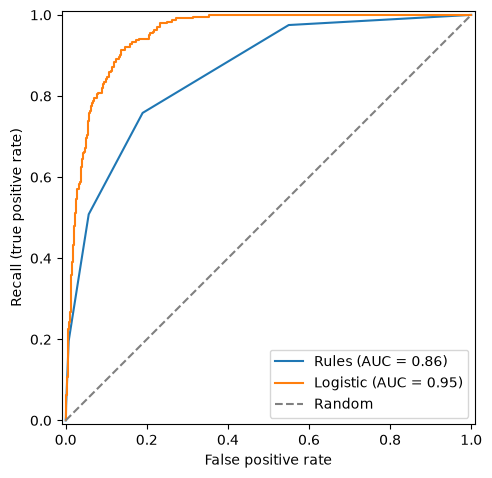

In [16]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(5, 5))
RocCurveDisplay.from_predictions(y_classification_test, rule_scores, ax=ax, name="Rules")
RocCurveDisplay.from_predictions(y_classification_test, overdue_probabilities, ax=ax, name="Logistic")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random")
ax.set_xlabel("False positive rate")
ax.set_ylabel("Recall (true positive rate)")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Pipeline — 지금까지의 단계를 하나로 묶기

5장에서 빈 값 채우기 → 표준화 → 모델을 따로 실행했다. **Pipeline**은 이 순서를 하나의 객체로 묶는다. `fit` 한 번이면 각 단계가 Train으로 차례로 배우고, `predict` 때는 배운 기준을 그대로 적용한다. 같은 일을 하는지 결과를 비교해 확인한다.

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
logistic_pipeline = Pipeline([
    ("preprocessing", clone(numeric_preprocessor)),   # clone: 같은 설정의 새 도구를 만든다
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
logistic_pipeline.fit(X_train, y_classification_train)   # 원본 X_train을 그대로 넣는다
pipeline_probabilities = logistic_pipeline.predict_proba(X_test)[:, 1]
print("따로 실행한 결과와의 최대 차이:", np.max(np.abs(overdue_probabilities - pipeline_probabilities)))

따로 실행한 결과와의 최대 차이: 0.0


**출력 읽기:** 차이가 0이다. Pipeline은 5장의 수동 실행과 똑같은 계산을 한다.

평가도 여러 번 반복할 것이므로 함수로 묶는다. 안에 든 계산은 4~6장에서 직접 해 본 것과 같다.

In [18]:
def evaluate_classifier(model_name, fitted_model, X_evaluation, y_evaluation):
    labels = fitted_model.predict(X_evaluation)
    probabilities = fitted_model.predict_proba(X_evaluation)[:, 1]
    return {
        "model": model_name,
        "accuracy": accuracy_score(y_evaluation, labels),
        "precision": precision_score(y_evaluation, labels, zero_division=0),
        "recall": recall_score(y_evaluation, labels),
        "f1": f1_score(y_evaluation, labels),
        "roc_auc": roc_auc_score(y_evaluation, probabilities),
    }

logistic_result = evaluate_classifier("Logistic", logistic_pipeline, X_test, y_classification_test)
display(pd.DataFrame([logistic_result]))

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic,0.9205,0.7077,0.575,0.6345,0.9505


## 8. 교차검증 — Test를 쓰지 않고 설정 비교하기

앞으로 "이 설정과 저 설정 중 무엇이 나은가"를 여러 번 비교한다. 매번 Test로 비교하면 결국 Test에 맞춘 선택이 되어, Test가 더 이상 공정한 시험이 아니게 된다.

**교차검증(5-fold)**은 Train 8,000명을 5묶음(**fold**)으로 나눈다. 한 묶음(1,600명)을 검증용으로 빼고 나머지 4묶음으로 학습하는 일을 5번 반복해 점수 5개를 얻는다. Test는 건드리지 않는다.

In [19]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

classification_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fold_scores = cross_val_score(logistic_pipeline, X_train, y_classification_train,
                              scoring="f1", cv=classification_cv)

display(pd.DataFrame({"fold": [1, 2, 3, 4, 5], "validation_f1": fold_scores}))
print("평균 F1:", fold_scores.mean(), " 표준편차:", fold_scores.std())

,fold,validation_f1
0,1,0.5906
1,2,0.5776
2,3,0.6647
3,4,0.6802
4,5,0.5872


평균 F1: 0.6200719950297173  표준편차: 0.04326645209517493


**출력 읽기:** 검증 묶음에 따라 F1이 조금씩 다르다. 앞으로 설정을 비교할 때는 이 5개의 평균을 쓴다. 차이가 표준편차보다 작다면 우연일 수 있다.

**확인 질문:** `cross_val_score`에 5장의 표준화된 `X_train_prepared`가 아니라 원본 `X_train`과 Pipeline을 넣은 이유는?
<details><summary>답 확인</summary>`X_train_prepared`는 Train 8,000명 전체의 평균으로 표준화됐다. 거기에는 검증 묶음 1,600명의 정보도 들어 있다. Pipeline을 넣으면 매 반복마다 학습용 4묶음으로만 평균을 다시 배우므로 검증 묶음이 진짜 "처음 보는 데이터"가 된다.</details>

## 9. 불균형 처리 — 적은 쪽(연체)에 더 신경 쓰게 하기

연체자는 12%뿐이라, 모델은 정상 고객을 맞히는 쪽으로 기울기 쉽다. 두 가지 대처법을 비교한다.

- **class_weight="balanced":** 연체자를 틀리면 더 크게 벌점을 준다. 데이터는 그대로다.
- **SMOTE:** 연체자들 사이에 비슷한 가짜 연체자를 만들어 Train의 비율을 맞춘다.

In [20]:
balanced_logistic = Pipeline([
    ("preprocessing", clone(numeric_preprocessor)),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000,
                                 random_state=RANDOM_STATE)),
])
balanced_logistic.fit(X_train, y_classification_train)
balanced_result = evaluate_classifier("Logistic + class_weight", balanced_logistic,
                                      X_test, y_classification_test)

SMOTE가 Train을 어떻게 바꾸는지 먼저 본다. 가짜 표본은 고객 사이의 거리로 만들기 때문에 표준화한 데이터에 적용한다.

In [21]:
from imblearn.over_sampling import SMOTE

X_resampled, y_resampled = SMOTE(random_state=RANDOM_STATE).fit_resample(
    X_train_prepared, y_classification_train)
display(pd.DataFrame({
    "before": y_classification_train.value_counts(),
    "after SMOTE": pd.Series(y_resampled).value_counts(),
}).rename(index={0: "정상", 1: "연체"}))

,before,after SMOTE
is_overdue,,
정상,7039,7039
연체,961,7039


**출력 읽기:** 연체자가 정상 고객 수만큼 늘었다. 늘어난 것은 실제 고객이 아니라 합성된 표본이다.

SMOTE도 Pipeline에 넣는다. 일반 Pipeline 대신 imbalanced-learn의 Pipeline을 쓰면 SMOTE는 `fit`(학습) 때만 실행되고 `predict`(예측) 때는 건너뛴다. Test는 실제 비율 그대로 채점해야 하기 때문이다.

In [22]:
from imblearn.pipeline import Pipeline as SamplingPipeline

smote_logistic = SamplingPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
smote_logistic.fit(X_train, y_classification_train)
smote_result = evaluate_classifier("Logistic + SMOTE", smote_logistic,
                                  X_test, y_classification_test)

classification_rows = [logistic_result, balanced_result, smote_result]
display(pd.DataFrame(classification_rows))

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic,0.9205,0.7077,0.575,0.6345,0.9505
1,Logistic + class_weight,0.8785,0.4965,0.875,0.6335,0.9505
2,Logistic + SMOTE,0.8845,0.5109,0.875,0.6452,0.9504


**출력 읽기:** 두 방법 모두 Recall이 크게 오르고 Precision이 내려갔다. 6장에서 임계값을 내렸을 때와 같은 방향이다. 반면 순서를 매기는 능력인 ROC-AUC는 세 모델이 거의 같다. 이 데이터에서 불균형 처리의 효과는 대부분 "판정 기준을 연체 쪽으로 옮긴 것"이다. 결과가 비슷하다면, 데이터를 바꾸지 않는 class_weight가 더 단순한 선택이다.

**확인 질문:** Test에도 SMOTE를 적용해 연체 비율을 50%로 맞추면 왜 안 될까?
<details><summary>답 확인</summary>실제 고객은 12%만 연체한다. 비율을 바꾼 시험지로 채점하면 실제 상황에서의 성능을 알 수 없다.</details>

## 10. 회귀 — 같은 입력으로 신용 점수 예측하기

이제 정답(y)만 신용 점수로 바꾼다. 회귀는 "얼마나 가깝게 맞혔나"로 평가한다.

- **MAE** = 오차(실제 − 예측) 크기의 평균. "평균 몇 점 틀렸나"
- **RMSE** = 오차를 제곱해 평균 낸 뒤 제곱근. 큰 오차에 더 민감하다. 단위는 MAE와 같은 "점"이다.
- **R²** = "모두에게 평균 점수를 예측하는 것"보다 얼마나 나은가. 1이면 완벽, 0이면 평균 예측과 같다.

비교 기준으로 모든 고객에게 Train 평균 점수를 예측하는 모델을 함께 만든다.

In [23]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

mean_regressor = DummyRegressor(strategy="mean")
mean_regressor.fit(X_train, y_regression_train)
mean_predictions = mean_regressor.predict(X_test)

linear_pipeline = Pipeline([
    ("preprocessing", clone(numeric_preprocessor)),
    ("model", LinearRegression()),
])
linear_pipeline.fit(X_train, y_regression_train)
linear_predictions = linear_pipeline.predict(X_test)

display(pd.DataFrame({
    "actual": y_regression_test.to_numpy()[:5],
    "mean_model": mean_predictions[:5],
    "linear_model": linear_predictions[:5],
}))

,actual,mean_model,linear_model
0,286.0,375.3211,322.1864
1,353.0,375.3211,365.9519
2,355.0,375.3211,349.7822
3,352.0,375.3211,394.2367
4,246.0,375.3211,237.4087


**출력 읽기:** 평균 모델은 모두에게 같은 점수를 주고, 선형 회귀는 고객마다 다른 점수를 준다. 이제 지표로 채점한다.

In [24]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate_regressor(model_name, actual_scores, predicted_scores):
    return {
        "model": model_name,
        "mae": mean_absolute_error(actual_scores, predicted_scores),
        "rmse": np.sqrt(mean_squared_error(actual_scores, predicted_scores)),
        "r2": r2_score(actual_scores, predicted_scores),
    }

regression_rows = [
    evaluate_regressor("Mean", y_regression_test, mean_predictions),
    evaluate_regressor("Linear", y_regression_test, linear_predictions),
]
display(pd.DataFrame(regression_rows))

,model,mae,rmse,r2
0,Mean,64.7302,80.8737,-0.0004
1,Linear,23.9327,30.1257,0.8612


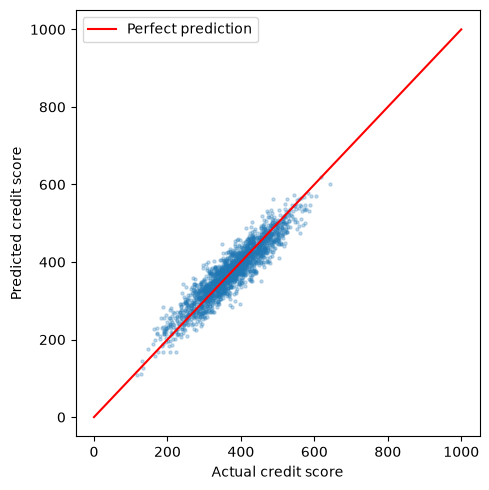

In [25]:
plt.figure(figsize=(5, 5))
plt.scatter(y_regression_test, linear_predictions, s=5, alpha=0.25)
plt.plot([0, 1000], [0, 1000], color="red", label="Perfect prediction")
plt.xlabel("Actual credit score")
plt.ylabel("Predicted credit score")
plt.legend()
plt.tight_layout()
plt.show()

**출력 읽기:** 점들이 빨간 대각선(완벽한 예측) 주변에 모여 있다. RMSE가 약 30인데, 데이터를 만들 때 넣은 잡음의 크기(표준편차 30)와 같다. 잡음은 어떤 모델로도 예측할 수 없으므로, 선형 회귀가 줄일 수 있는 오차는 거의 다 줄였다는 뜻이다. 평균 모델의 R²가 0보다 아주 조금 작은 것은 Test가 아니라 Train의 평균을 예측했기 때문이다.

### 10-1. 과대적합 확인 — Train과 Test 오차 비교

**과대적합**은 모델이 학습 데이터의 잡음까지 외워서, 학습 데이터에서는 잘 맞는데 새 데이터에서는 덜 맞는 상태다. 그래서 Train 오차와 Test 오차의 차이로 확인한다.

In [26]:
linear_train_rmse = np.sqrt(mean_squared_error(y_regression_train, linear_pipeline.predict(X_train)))
linear_test_rmse = np.sqrt(mean_squared_error(y_regression_test, linear_predictions))
print("선형 회귀 Train RMSE:", linear_train_rmse)
print("선형 회귀 Test RMSE:", linear_test_rmse)

선형 회귀 Train RMSE: 29.54730248578239
선형 회귀 Test RMSE: 30.1256653152408


**출력 읽기:** 두 오차가 거의 같다. 변수 6개에 학습 고객 8,000명이면, 선형 모델이 잡음을 외울 여지가 거의 없다. 이 데이터의 선형 회귀는 과대적합이 아니다. 다음 절의 규제는 과대적합을 줄이는 대표적인 방법이므로, 여기서는 성능을 크게 바꾸지 못할 것이라고 예상할 수 있다.

### 10-2. 규제 — 쓸모없는 변수의 영향 줄이기

선형 회귀는 변수마다 **계수**(그 변수가 1 표준편차 커질 때 점수가 몇 점 변하는가)를 배운다. 계수가 지나치게 커지면 학습 데이터의 우연한 패턴에 민감해져 과대적합이 생긴다. **규제**는 계수가 커지는 것에 벌점을 줘서, 도움이 적은 변수의 계수를 작게 만든다. 벌점의 세기는 **Alpha**로 정한다.

- **Lasso:** 계수를 정확히 0으로 만들 수 있다. 그 변수를 아예 안 쓰게 된다.
- **Ridge:** 계수를 줄이기만 하고 0으로 만들지는 않는다.

In [27]:
from sklearn.linear_model import Ridge, Lasso

alpha_values = [0.01, 0.1, 1, 10, 100]
ridge_coefficients = []
lasso_coefficients = []

for alpha in alpha_values:
    ridge_pipeline = Pipeline([
        ("preprocessing", clone(numeric_preprocessor)),
        ("model", Ridge(alpha=alpha)),
    ])
    ridge_pipeline.fit(X_train, y_regression_train)
    ridge_coefficients.append(ridge_pipeline.named_steps["model"].coef_)

    lasso_pipeline = Pipeline([
        ("preprocessing", clone(numeric_preprocessor)),
        ("model", Lasso(alpha=alpha, max_iter=50_000)),
    ])
    lasso_pipeline.fit(X_train, y_regression_train)
    lasso_coefficients.append(lasso_pipeline.named_steps["model"].coef_)

ridge_coefficient_table = pd.DataFrame(ridge_coefficients, index=alpha_values, columns=feature_columns)
lasso_coefficient_table = pd.DataFrame(lasso_coefficients, index=alpha_values, columns=feature_columns)
lasso_coefficient_table.index.name = "alpha"
display(lasso_coefficient_table)

,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m
alpha,,,,,,
0.01,-0.2196,58.0048,-0.1588,-28.7729,0.1607,-35.8611
0.10,-0.1325,57.9179,-0.0674,-28.6786,0.0725,-35.7729
1.00,-0.0000,57.0237,-0.0000,-27.7773,0.0000,-34.8679
10.00,-0.0000,48.0446,0.0000,-18.8133,0.0000,-25.7900
100.00,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


**출력 읽기 (Lasso 표):** 한 행이 Alpha 하나다. Alpha = 1에서 나이·소비 점수·카드 수의 계수가 0이 된다(`-0.0000`도 0이다). 1장에서 말한 "정답에 쓰이지 않은 변수" 세 개를 모델이 스스로 골라낸 것이다. Alpha = 100에서는 모든 계수가 0이 되어, 모두에게 같은 점수를 주는 평균 모델과 같아진다. 아래 그래프로 두 방법을 비교한다.

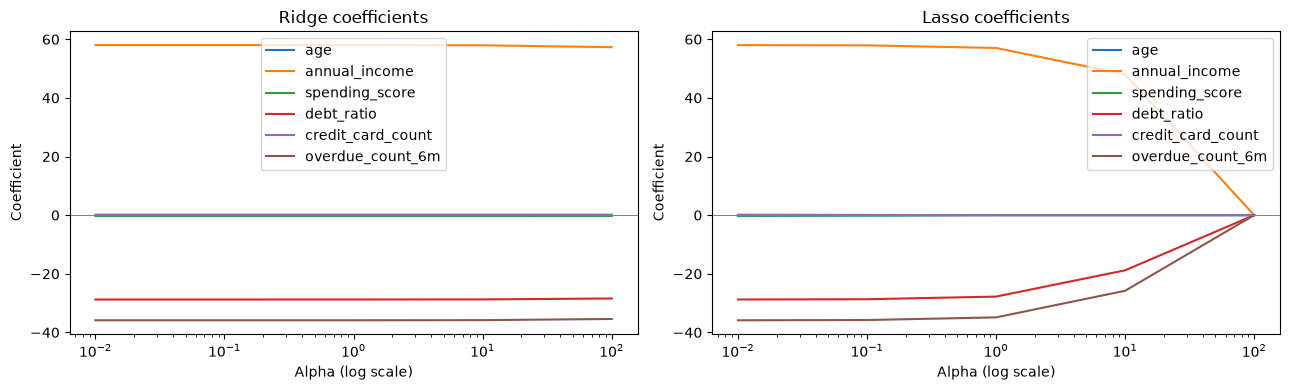

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ridge_coefficient_table.plot(ax=axes[0], logx=True, title="Ridge coefficients")
lasso_coefficient_table.plot(ax=axes[1], logx=True, title="Lasso coefficients")
for axis in axes:
    axis.set_xlabel("Alpha (log scale)")
    axis.set_ylabel("Coefficient")
    axis.axhline(0, color="gray", linewidth=0.7)
plt.tight_layout()
plt.show()

**출력 읽기:** Lasso는 Alpha가 커지면 계수가 하나씩 0으로 떨어진다. Ridge는 이 범위에서 거의 변하지 않는다. scikit-learn에서는 같은 Alpha 값이라도 Ridge 쪽 벌점이 데이터 수만큼 상대적으로 약하기 때문이다. Alpha의 숫자 크기를 두 모델 사이에 그대로 비교하지 않는다.

### 10-3. Alpha 고르기 — 8장의 교차검증 사용

Alpha를 Test나 그래프를 보고 고르지 않는다. **GridSearchCV**는 후보마다 8장의 교차검증을 실행해 평균 점수가 가장 좋은 후보를 고르는 도구다. 마지막에 그 설정으로 Train 전체를 다시 학습한다.

`model__alpha`는 Pipeline 안 "model" 단계의 alpha라는 뜻이다. 점수 이름 `neg_root_mean_squared_error`는 RMSE에 마이너스를 붙인 것이다. 이 도구는 "점수가 클수록 좋다"고 가정하기 때문이다.

In [29]:
from sklearn.model_selection import GridSearchCV, KFold

regression_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ridge_search = GridSearchCV(
    Pipeline([("preprocessing", clone(numeric_preprocessor)), ("model", Ridge())]),
    param_grid={"model__alpha": alpha_values},
    scoring="neg_root_mean_squared_error", cv=regression_cv,
)
ridge_search.fit(X_train, y_regression_train)

lasso_search = GridSearchCV(
    Pipeline([("preprocessing", clone(numeric_preprocessor)),
              ("model", Lasso(max_iter=50_000))]),
    param_grid={"model__alpha": alpha_values},
    scoring="neg_root_mean_squared_error", cv=regression_cv,
)
lasso_search.fit(X_train, y_regression_train)

print("Ridge가 고른 Alpha:", ridge_search.best_params_["model__alpha"])
print("Lasso가 고른 Alpha:", lasso_search.best_params_["model__alpha"])
regression_rows.append(evaluate_regressor("Ridge (CV)", y_regression_test, ridge_search.predict(X_test)))
regression_rows.append(evaluate_regressor("Lasso (CV)", y_regression_test, lasso_search.predict(X_test)))
display(pd.DataFrame(regression_rows))

Ridge가 고른 Alpha: 1
Lasso가 고른 Alpha: 0.1


,model,mae,rmse,r2
0,Mean,64.7302,80.8737,-0.0004
1,Linear,23.9327,30.1257,0.8612
2,Ridge (CV),23.9328,30.1259,0.8612
3,Lasso (CV),23.9297,30.1284,0.8612


**출력 읽기:** 10-1에서 예상한 대로, 규제를 넣어도 Test 오차는 선형 회귀와 거의 같다. 줄일 과대적합이 없고, 쓸모없는 변수의 계수도 원래 작았기 때문이다. 이 데이터에서 규제의 쓸모는 성능보다 "어떤 변수가 필요 없는지 알려준다"(10-2의 Lasso 표)는 데 있다.

**확인 질문:** Lasso의 계수가 모두 0이 되면 어떤 예측이 남을까?
<details><summary>답 확인</summary>계수가 모두 0이면 입력과 상관없이 절편(Train 평균 점수)만 남는다. 모든 고객에게 같은 점수를 주므로 평균 모델과 같아진다. Alpha가 클수록 좋은 것이 아니다.</details>

### 10-4. 같은 고객, 두 가지 예측 — 회귀와 분류 비교

같은 입력으로 만든 두 모델을 한 고객씩 나란히 놓는다. 1장에서 본 대로 연체 라벨은 "신용 점수가 하위 15% 기준점보다 낮은가"로 만들어졌다. 기준점 근처 고객을 골라 본다.

In [30]:
score_threshold = customers["credit_score"].quantile(0.15)   # 데이터 생성에 쓰인 연체 기준점
print("연체 기준점(하위 15% 점수):", score_threshold)

side_by_side = pd.DataFrame({
    "actual_score": y_regression_test.to_numpy(),
    "predicted_score": linear_predictions,
    "actual_overdue": y_test_array,
    "overdue_probability": pipeline_probabilities,
})
is_near = (side_by_side["actual_score"] - score_threshold).abs().to_numpy() <= 20
print("기준점 ±20점 안의 Test 고객:", is_near.sum(), "/", len(side_by_side))
display(side_by_side[is_near].head(8))

logistic_wrong = logistic_pipeline.predict(X_test) != y_test_array
print("기준점 근처 고객의 분류 오류율:", logistic_wrong[is_near].mean())
print("나머지 고객의 분류 오류율:", logistic_wrong[~is_near].mean())

연체 기준점(하위 15% 점수): 292.0
기준점 ±20점 안의 Test 고객: 244 / 2000


,actual_score,predicted_score,actual_overdue,overdue_probability
0,286.0,322.1864,1,0.1194
23,277.0,278.4475,1,0.4289
25,303.0,338.9280,0,0.0666
29,299.0,311.1876,0,0.1629
49,306.0,334.4918,0,0.0880
55,297.0,277.1892,0,0.4812
56,291.0,307.2753,1,0.2316
62,291.0,339.2287,1,0.0702


기준점 근처 고객의 분류 오류율: 0.3360655737704918
나머지 고객의 분류 오류율: 0.043849658314350795


**출력 읽기:** 회귀 쪽에서 20~30점 오차는 RMSE 수준의 평범한 오차다. 하지만 기준점 근처 고객은 점수가 조금만 달라도 정상/연체가 바뀐다. 게다가 기준점 아래 고객도 80%만 연체로 표시됐다. 그래서 분류 모델은 이 구간에서 훨씬 자주 틀린다(오류율 약 34% vs 나머지 약 4%).

| | 회귀 (신용 점수) | 분류 (연체 여부) |
| --- | --- | --- |
| 출력 | 숫자 하나 (점) | 연체 확률 → 임계값으로 0/1 |
| 평가 | 얼마나 가깝나: MAE·RMSE(점), R² | 맞았나 틀렸나: 혼동행렬, Precision·Recall·F1, 순서: AUC |
| 이 데이터에서 어려운 점 | 잡음 30점은 줄일 수 없다 | 연체자가 12%뿐이고, 기준점 근처가 헷갈린다 |

**확인 질문:** 신용 점수를 예측하는 회귀 모델이 있으니 "예측 점수 < 기준점이면 연체"로 분류하면 되지 않을까? 무엇이 아쉬울까?
<details><summary>답 확인</summary>가능하다. 이 데이터에서는 오히려 5장의 0.5 기준 로지스틱 회귀보다 F1이 높게 나온다. 연체 라벨 자체를 점수로 만들었기 때문이다. 실제 데이터에서는 연체가 점수 하나로 정해지지 않는다. 또 회귀는 모든 점수 구간의 오차를 똑같이 줄이려 하고, 분류는 정상/연체를 가르는 경계에 집중한다. 그리고 분류 모델은 "얼마나 위험한가"를 확률로 주므로 6장처럼 임계값을 업무 목적에 맞게 조절할 수 있다. 무엇을 예측하고 어떻게 쓸지에 따라 문제 유형과 지표를 고른다.</details>

## 정리

| 장 | 해 본 것 | 기억할 것 |
| --- | --- | --- |
| 1~2 | 입력/정답 구분, Train/Test 분할 | 정답은 입력에 넣지 않는다. Test는 마지막 채점에만 쓴다 |
| 3~4 | 규칙 베이스라인, 혼동행렬 | Accuracy만 보면 속는다. Precision·Recall·F1을 함께 본다 |
| 5~6 | 로지스틱 회귀, 임계값, ROC-AUC | 판정 = 확률 + 임계값. AUC는 임계값과 무관한 순서 능력이다 |
| 7~8 | Pipeline, 교차검증 | 전처리 기준도 학습의 일부다. 설정 비교는 Train 안에서 한다 |
| 9 | class_weight, SMOTE | 효과는 주로 판정 기준을 연체 쪽으로 옮기는 것 |
| 10 | 선형 회귀, 과대적합 확인, Ridge·Lasso, 회귀와 분류 비교 | 회귀는 오차 크기로 평가한다. 규제는 과대적합을 줄이는 도구이고, Lasso는 쓸모없는 변수를 0으로 만든다. 같은 입력이라도 문제 유형에 따라 출력·지표·해석이 다르다 |

여기까지 Test는 각 모델을 채점할 때만 썼다. 다만 여러 모델의 Test 점수를 계속 비교해 하나를 고르면, 그것도 Test에 맞춘 선택이 된다. 최종 모델은 교차검증 점수로 고른다.

---

# 부록 — 더 알아보기

본편을 이해했다면 이어서 본다. 각 부록은 본편의 결과를 사용하므로 본편을 먼저 실행해야 한다. A와 B는 이어서 실행한다.

## A. 앙상블 — Random Forest와 GridSearchCV

**Random Forest(RF)**는 조금씩 다르게 학습한 결정 나무 여러 그루의 판정을 모으는 모델이다. 나무 한 그루보다 덜 흔들린다. 먼저 기본 설정을 교차검증으로 평가하고, GridSearchCV로 설정을 탐색해 비교한다. 설명이 목적이므로 탐색은 8가지 조합으로 작게 잡았다.

In [31]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import ParameterGrid

default_forest = Pipeline([
    ("preprocessing", clone(numeric_preprocessor)),
    ("model", RandomForestClassifier(class_weight="balanced",
                                      random_state=RANDOM_STATE, n_jobs=2)),
])
default_forest_cv = cross_val_score(default_forest, X_train, y_classification_train,
                                    scoring="f1", cv=classification_cv)
default_forest.fit(X_train, y_classification_train)
print("기본 RF 교차검증 F1:", default_forest_cv.mean())

기본 RF 교차검증 F1: 0.6576629296774489


In [32]:
forest_grid = {
    "model__n_estimators": [100, 200],     # 나무 수
    "model__max_depth": [8, 12],           # 나무 깊이 제한
    "model__min_samples_leaf": [1, 5],     # 마지막 칸에 남길 최소 고객 수
}
print("탐색 조합 수:", len(ParameterGrid(forest_grid)))
forest_search = GridSearchCV(clone(default_forest), param_grid=forest_grid,
                             scoring="f1", cv=classification_cv)
forest_search.fit(X_train, y_classification_train)
tuned_forest = forest_search.best_estimator_
print("고른 설정:", forest_search.best_params_)
print("고른 설정의 교차검증 F1:", forest_search.best_score_)

탐색 조합 수: 8


고른 설정: {'model__max_depth': 12, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
고른 설정의 교차검증 F1: 0.6670890061138851


In [33]:
classification_rows.append(evaluate_classifier("RF default", default_forest, X_test, y_classification_test))
classification_rows.append(evaluate_classifier("RF tuned", tuned_forest, X_test, y_classification_test))
display(pd.DataFrame(classification_rows))

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic,0.9205,0.7077,0.5750,0.6345,0.9505
1,Logistic + class_weight,0.8785,0.4965,0.8750,0.6335,0.9505
2,Logistic + SMOTE,0.8845,0.5109,0.8750,0.6452,0.9504
3,RF default,0.9105,0.6041,0.7375,0.6642,0.9388
4,RF tuned,0.8985,0.5539,0.7917,0.6518,0.9399


**출력 읽기:** 교차검증에서는 튜닝한 RF가 조금 나았는데, Test F1은 오히려 기본 RF보다 낮다. 두 차이(0.01 안팎)는 8장에서 본 fold 사이의 흔들림(표준편차 약 0.04)보다 작아서, 어느 쪽이 낫다고 말하기 어렵다. 또 F1은 RF가 높아도 ROC-AUC는 로지스틱 회귀가 더 높다. 이 데이터는 변수의 단순한 합으로 만들어졌기 때문에 선형 모델과 잘 맞는다. 앙상블이 언제나 이기는 것은 아니다.

## B. 승인·보류·거절 — 임계값 두 개 정하기

6장에서는 임계값 하나로 0/1을 나눴다. 대출 심사라면 기준을 두 개 두고 세 구간으로 나눌 수 있다.

- 연체 확률 < 보류 기준 → **승인**
- 보류 기준 ≤ 확률 < 거절 기준 → **보류**(사람이 심사)
- 확률 ≥ 거절 기준 → **거절**

기준은 Test가 아니라 Train으로 정한다. **OOF(out-of-fold) 예측**은 8장의 교차검증처럼 Train 고객 각자를, 그 고객을 빼고 학습한 모델로 예측한 확률이다. 이렇게 하면 Train으로도 "처음 보는 고객"에 대한 확률을 얻는다.

In [34]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

oof_probabilities = cross_val_predict(
    clone(tuned_forest), X_train, y_classification_train,
    cv=classification_cv, method="predict_proba",
)[:, 1]

# 가능한 모든 임계값에서의 Precision·Recall을 한 번에 계산한다.
# 마지막 Precision·Recall 값에는 대응하는 임계값이 없어서 [:-1]로 맞춘다.
precision_values, recall_values, thresholds = precision_recall_curve(
    y_classification_train, oof_probabilities)
precision_values = precision_values[:-1]
recall_values = recall_values[:-1]

f1_values = 2 * precision_values * recall_values / np.clip(precision_values + recall_values, 1e-12, None)
reject_threshold = thresholds[np.argmax(f1_values)]                # F1이 가장 높은 기준
hold_threshold = thresholds[recall_values >= 0.95].max()           # 연체자 95% 이상을 보류 이상으로 보내는 가장 높은 기준
hold_threshold = min(hold_threshold, reject_threshold)
print("보류 기준:", hold_threshold)
print("거절 기준:", reject_threshold)

보류 기준: 0.17332336138298451
거절 기준: 0.4926484065435953


In [35]:
test_risk_probabilities = tuned_forest.predict_proba(X_test)[:, 1]
policy_labels = np.full(len(X_test), "hold", dtype=object)
policy_labels[test_risk_probabilities < hold_threshold] = "approve"
policy_labels[test_risk_probabilities >= reject_threshold] = "reject"

policy_rows = []
for band_name in ["approve", "hold", "reject"]:
    band_mask = policy_labels == band_name
    customer_count = int(band_mask.sum())
    overdue_count = int(y_test_array[band_mask].sum())
    policy_rows.append({"band": band_name, "customers": customer_count,
                        "overdue": overdue_count, "overdue_rate": overdue_count / customer_count})
display(pd.DataFrame(policy_rows))

,band,customers,overdue,overdue_rate
0,approve,1426,15,0.0105
1,hold,224,34,0.1518
2,reject,350,191,0.5457


**출력 읽기:** 승인 구간의 연체율은 약 1%로 낮고, 거절 구간은 절반 이상이 실제 연체자다. 보류 구간은 사람이 심사할 고객 수다.

**확인 질문:** 보류 기준을 더 낮추면 무엇을 얻고 무엇을 잃을까?
<details><summary>답 확인</summary>자동 승인에 섞이는 연체자는 줄지만, 보류로 넘어가는 고객이 늘어 심사 인력이 더 필요하다. 실제 기준은 연체 손실액, 심사 비용, 거절로 잃는 고객의 가치를 함께 따져 정한다.</details>

## C. 특징 중요도 — 모델은 어떤 변수를 많이 썼나

RF는 나무를 만들 때 각 변수가 고객을 나누는 데 얼마나 기여했는지 기록한다. 1장에서 정답 생성에 쓰인 변수(소득·부채 비율·연체 횟수)와 비교한다.

In [36]:
importance_table = pd.DataFrame({
    "feature": feature_columns,
    "importance": tuned_forest.named_steps["model"].feature_importances_,
}).sort_values("importance", ascending=False)
display(importance_table)

,feature,importance
1,annual_income,0.4693
5,overdue_count_6m,0.2125
3,debt_ratio,0.1694
2,spending_score,0.0632
0,age,0.0544
4,credit_card_count,0.0311


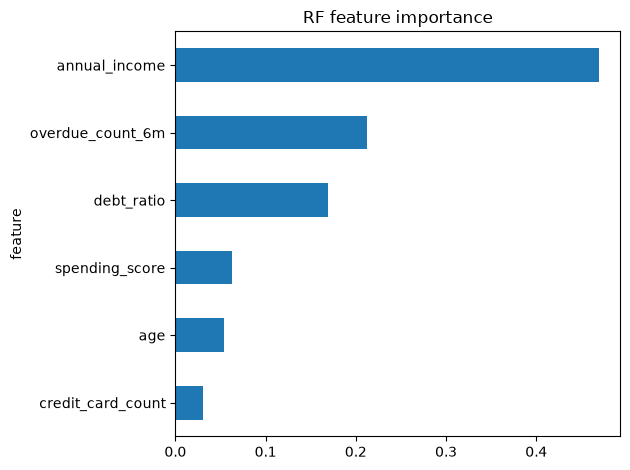

In [37]:
importance_table.plot.barh(x="feature", y="importance", legend=False, title="RF feature importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**출력 읽기:** 상위 세 변수가 정답 생성에 쓰인 세 변수와 같다. 쓰이지 않은 세 변수도 0은 아니다. 이 방식은 값의 종류가 많은 변수를 부풀리는 경향이 있기 때문이다. 중요도는 "모델이 많이 쓴 정도"이지 "그 변수가 연체의 원인"이라는 뜻이 아니다.

## D. Learning Curve — 데이터가 많아지면 나아질까

Train의 20%, 50%, 100%만 써서 학습하고, 각 크기에서 학습한 데이터의 점수(Train)와 교차검증 점수(Validation)를 비교한다.

- 두 선의 간격이 크면, 학습 데이터를 외워서 새 데이터에서는 덜 맞는다(**과대적합**).
- 두 선이 붙어 있는데 점수가 낮으면, 모델이나 데이터 자체의 한계다.

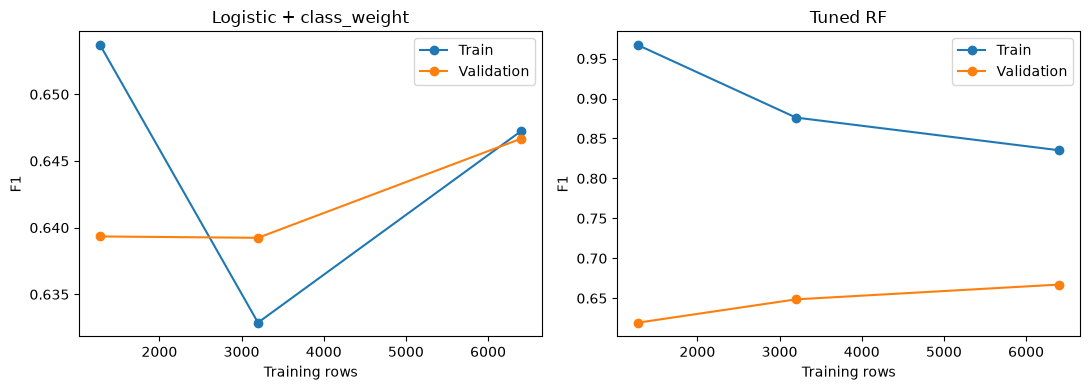

In [38]:
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
curve_models = [("Logistic + class_weight", balanced_logistic), ("Tuned RF", tuned_forest)]
for axis, (model_name, estimator) in zip(axes, curve_models):
    sizes, train_scores, validation_scores = learning_curve(
        clone(estimator), X_train, y_classification_train,
        train_sizes=[0.2, 0.5, 1.0], cv=classification_cv, scoring="f1",
    )
    axis.plot(sizes, train_scores.mean(axis=1), marker="o", label="Train")
    axis.plot(sizes, validation_scores.mean(axis=1), marker="o", label="Validation")
    axis.set_title(model_name)
    axis.set_xlabel("Training rows")
    axis.set_ylabel("F1")
    axis.legend()
plt.tight_layout()
plt.show()

**출력 읽기:** 로지스틱 회귀는 두 선이 붙어 있다. 데이터를 더 모아도 크게 나아지지 않는다. RF는 Train 점수가 훨씬 높아 간격이 크다. 깊은 나무가 학습 데이터의 잡음까지 외운 것이다.

## E. 범주형 변수와 나만의 변환기(Custom Transformer)

지금까지 입력은 모두 숫자였다. "20대·30대" 같은 **범주형** 변수는 모델에 넣기 전에 숫자로 바꿔야 한다. 연습을 위해 나이로 연령대 열을, 소득 × 부채 비율로 부채액 열을 만든다. CSV는 바꾸지 않고 계산만 한다. 입력이 달라졌으므로 본편 모델과 같은 점수가 나와야 하는 실험은 아니다.

먼저 보통 함수로 "표 → 새 열이 붙은 표"를 확인한다.

In [39]:
def add_derived_features(input_frame):
    result = input_frame.copy()
    age_bins = [20, 30, 40, 50, 60, 70]
    age_labels = ["20-29", "30-39", "40-49", "50-59", "60-69"]
    age_groups = pd.cut(result["age"], bins=age_bins, labels=age_labels, right=False)
    result["age_group"] = age_groups.astype(object).where(age_groups.notna(), np.nan)
    result["debt_amount"] = result["annual_income"] * result["debt_ratio"]
    return result

display(add_derived_features(X_train.head()))

,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m,age_group,debt_amount
1559,40,4613.0,16,0.98,7,0,40-49,4520.74
7318,40,5914.0,57,0.83,1,0,40-49,4908.62
4825,22,3466.0,11,0.90,2,0,20-29,3119.40
606,49,5333.0,17,0.48,9,0,40-49,2559.84
2383,38,1500.0,27,0.82,8,0,30-39,1230.00


이 함수를 Pipeline에 넣으려면 `fit`과 `transform`을 가진 클래스로 감싼다. 이것이 **Custom Transformer**다. 이 변환은 Train에서 배울 것이 없으므로 `fit`은 아무것도 하지 않고 자기 자신을 돌려준다.

범주형 열은 **원-핫 인코딩**으로 바꾼다. 연령대 하나를 "20-29인가? 30-39인가? …" 0/1 열 여러 개로 펼치는 방식이다. `ColumnTransformer`는 숫자 열과 범주 열에 서로 다른 전처리를 적용한다.

In [40]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

class LearningDerivedFeatures(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return add_derived_features(X)

numeric_columns = feature_columns + ["debt_amount"]
categorical_columns = ["age_group"]
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
column_preprocessor = ColumnTransformer([
    ("numeric", clone(numeric_preprocessor), numeric_columns),
    ("categorical", categorical_preprocessor, categorical_columns),
])
extended_logistic = Pipeline([
    ("derive", LearningDerivedFeatures()),
    ("columns", column_preprocessor),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000,
                                 random_state=RANDOM_STATE)),
])
extended_logistic.fit(X_train, y_classification_train)
display(extended_logistic.named_steps["columns"].get_feature_names_out())
display(pd.DataFrame([balanced_result,
                      evaluate_classifier("Logistic + class_weight + derived", extended_logistic,
                                          X_test, y_classification_test)]))

array(['numeric__age', 'numeric__annual_income',
       'numeric__spending_score', 'numeric__debt_ratio',
       'numeric__credit_card_count', 'numeric__overdue_count_6m',
       'numeric__debt_amount', 'categorical__age_group_20-29',
       'categorical__age_group_30-39', 'categorical__age_group_40-49',
       'categorical__age_group_50-59', 'categorical__age_group_60-69'],
      dtype=object)

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic + class_weight,0.8785,0.4965,0.875,0.6335,0.9505
1,Logistic + class_weight + derived,0.8770,0.4930,0.875,0.6306,0.9495


**출력 읽기:** 연령대 한 열이 `age_group_20-29` 같은 0/1 열 다섯 개로 펼쳐졌다. 점수는 새 열이 없을 때와 거의 같다. 연령대와 부채액은 정답을 만들 때 쓰이지 않은 정보이기 때문이다. 실제 대출 심사에서는 나이 같은 정보를 쓰는 것 자체가 공정성 검토 대상이 된다.